# Análisis exploratorio de datos: precios de viviendas

Este notebook explora los datos de entrenamiento y prueba del proyecto para entender su estructura y el comportamiento de la variable a predecir (`SalePrice`), antes de construir cualquier modelo.

## 1. Librerías

Se cargan las librerías del ecosistema PyData que se usarán en el análisis:

- **numpy** y **pandas**: manejo de datos numéricos y tablas.
- **scipy.stats**: pruebas y medidas estadísticas.
- **matplotlib** y **seaborn**: gráficas.
- **scikit-learn**: herramientas de modelado y preprocesamiento.

También se define un estilo uniforme para las gráficas y se configura pandas para mostrar todas las columnas.

In [1]:
# Librerías PyData
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

%matplotlib inline
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 2. Carga de datos

Se leen los archivos de entrenamiento (`train`) y prueba (`test`). Las rutas no están fijas en el código, por lo que el notebook funciona aunque cambie la ubicación de los datos:

- La raíz del proyecto se detecta automáticamente buscando el archivo `pyproject.toml`.
- La carpeta de datos es `data/raw/` por defecto. Para usar otra, basta con definir la variable de entorno `DATA_DIR`.
- Los nombres de los archivos se ajustan en `TRAIN_FILE` y `TEST_FILE`.

Al final se muestra el tamaño de cada conjunto (filas, columnas).

In [2]:
# Carga de datos: rutas configurables
import os
from pathlib import Path

# Raíz del proyecto: primera carpeta hacia arriba que contenga pyproject.toml
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())

# Carpeta de datos: se puede cambiar con la variable de entorno DATA_DIR
DATA_DIR = Path(os.getenv("DATA_DIR", PROJECT_ROOT / "data" / "raw"))
TRAIN_FILE = "train.csv"
TEST_FILE = "test.csv"

train = pd.read_csv(DATA_DIR / TRAIN_FILE)
test = pd.read_csv(DATA_DIR / TEST_FILE)

print(f"Train: {train.shape}")
print(f"Test:  {test.shape}")

Train: (1460, 81)
Test:  (1459, 80)


## 3. Análisis de la variable objetivo: `SalePrice`

`SalePrice` es el precio de venta de cada vivienda y es la variable que el modelo deberá predecir. Solo existe en el conjunto de entrenamiento.

La gráfica de densidad muestra cómo se distribuyen los precios: dónde se concentran la mayoría de las viviendas y si hay valores extremos. Las líneas punteadas marcan la **media** (rojo) y la **mediana** (verde); si la media queda claramente a la derecha de la mediana, la distribución tiene una cola de precios altos (asimetría positiva).

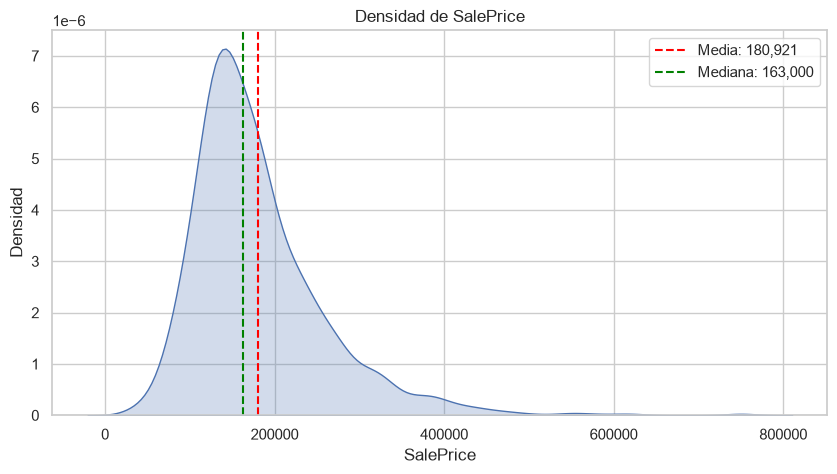

In [3]:
# Análisis de la variable target: densidad de SalePrice
TARGET = "SalePrice"

fig, ax = plt.subplots(figsize=(10, 5))
sns.kdeplot(train[TARGET], fill=True, ax=ax)
ax.axvline(train[TARGET].mean(), color="red", linestyle="--", label=f"Media: {train[TARGET].mean():,.0f}")
ax.axvline(train[TARGET].median(), color="green", linestyle="--", label=f"Mediana: {train[TARGET].median():,.0f}")
ax.set_title(f"Densidad de {TARGET}")
ax.set_xlabel(TARGET)
ax.set_ylabel("Densidad")
ax.legend()
plt.show()

## 4. Clasificación de variables numéricas: discretas y continuas

Las variables numéricas se separan en dos grupos, porque cada tipo se analiza mejor con una gráfica distinta:

- **Discretas**: toman pocos valores posibles, generalmente conteos o categorías codificadas con números (por ejemplo, número de baños, calidad general del 1 al 10 o mes de venta).
- **Continuas**: toman muchos valores distintos, como áreas, años o medidas.

Una variable se considera discreta si tiene **15 valores distintos o menos** (`MAX_DISCRETE_VALUES`). Como toda regla automática tiene excepciones, la lista `FORCE_CONTINUOUS` permite marcar variables que deben tratarse como continuas aunque tengan pocos valores. Es el caso de `PoolArea`: es un área, pero casi todas las viviendas no tienen piscina y por eso tiene pocos valores distintos.

Se excluye la columna `Id`, que solo identifica cada registro y no aporta información sobre el precio.

In [4]:
# Separación de variables numéricas en discretas y continuas
MAX_DISCRETE_VALUES = 15
FORCE_CONTINUOUS = ["PoolArea"]

numeric_cols = train.select_dtypes(include="number").columns.drop(["Id", TARGET])
n_unique = train[numeric_cols].nunique()

discretas = [col for col in numeric_cols if n_unique[col] <= MAX_DISCRETE_VALUES and col not in FORCE_CONTINUOUS]
continuas = [col for col in numeric_cols if col not in discretas]

print(f"Discretas ({len(discretas)}): {discretas}")
print(f"Continuas ({len(continuas)}): {continuas}")

Discretas (14): ['MSSubClass', 'OverallQual', 'OverallCond', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageCars', 'MoSold', 'YrSold']
Continuas (22): ['LotFrontage', 'LotArea', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'GarageYrBlt', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal']


## 5. Relación de las variables continuas con `SalePrice`

Se genera un gráfico de dispersión (scatter plot) por cada variable continua, con la variable en el eje X y `SalePrice` en el eje Y. Cada punto es una vivienda. Así se ve a simple vista si el precio sube o baja cuando cambia la variable.

El título de cada gráfica muestra el **coeficiente de correlación de Pearson (ρ)**, que mide qué tan fuerte es la relación lineal entre ambas variables:

- **ρ cercano a 1**: cuando la variable aumenta, el precio también aumenta.
- **ρ cercano a -1**: cuando la variable aumenta, el precio disminuye.
- **ρ cercano a 0**: no hay una relación lineal clara.

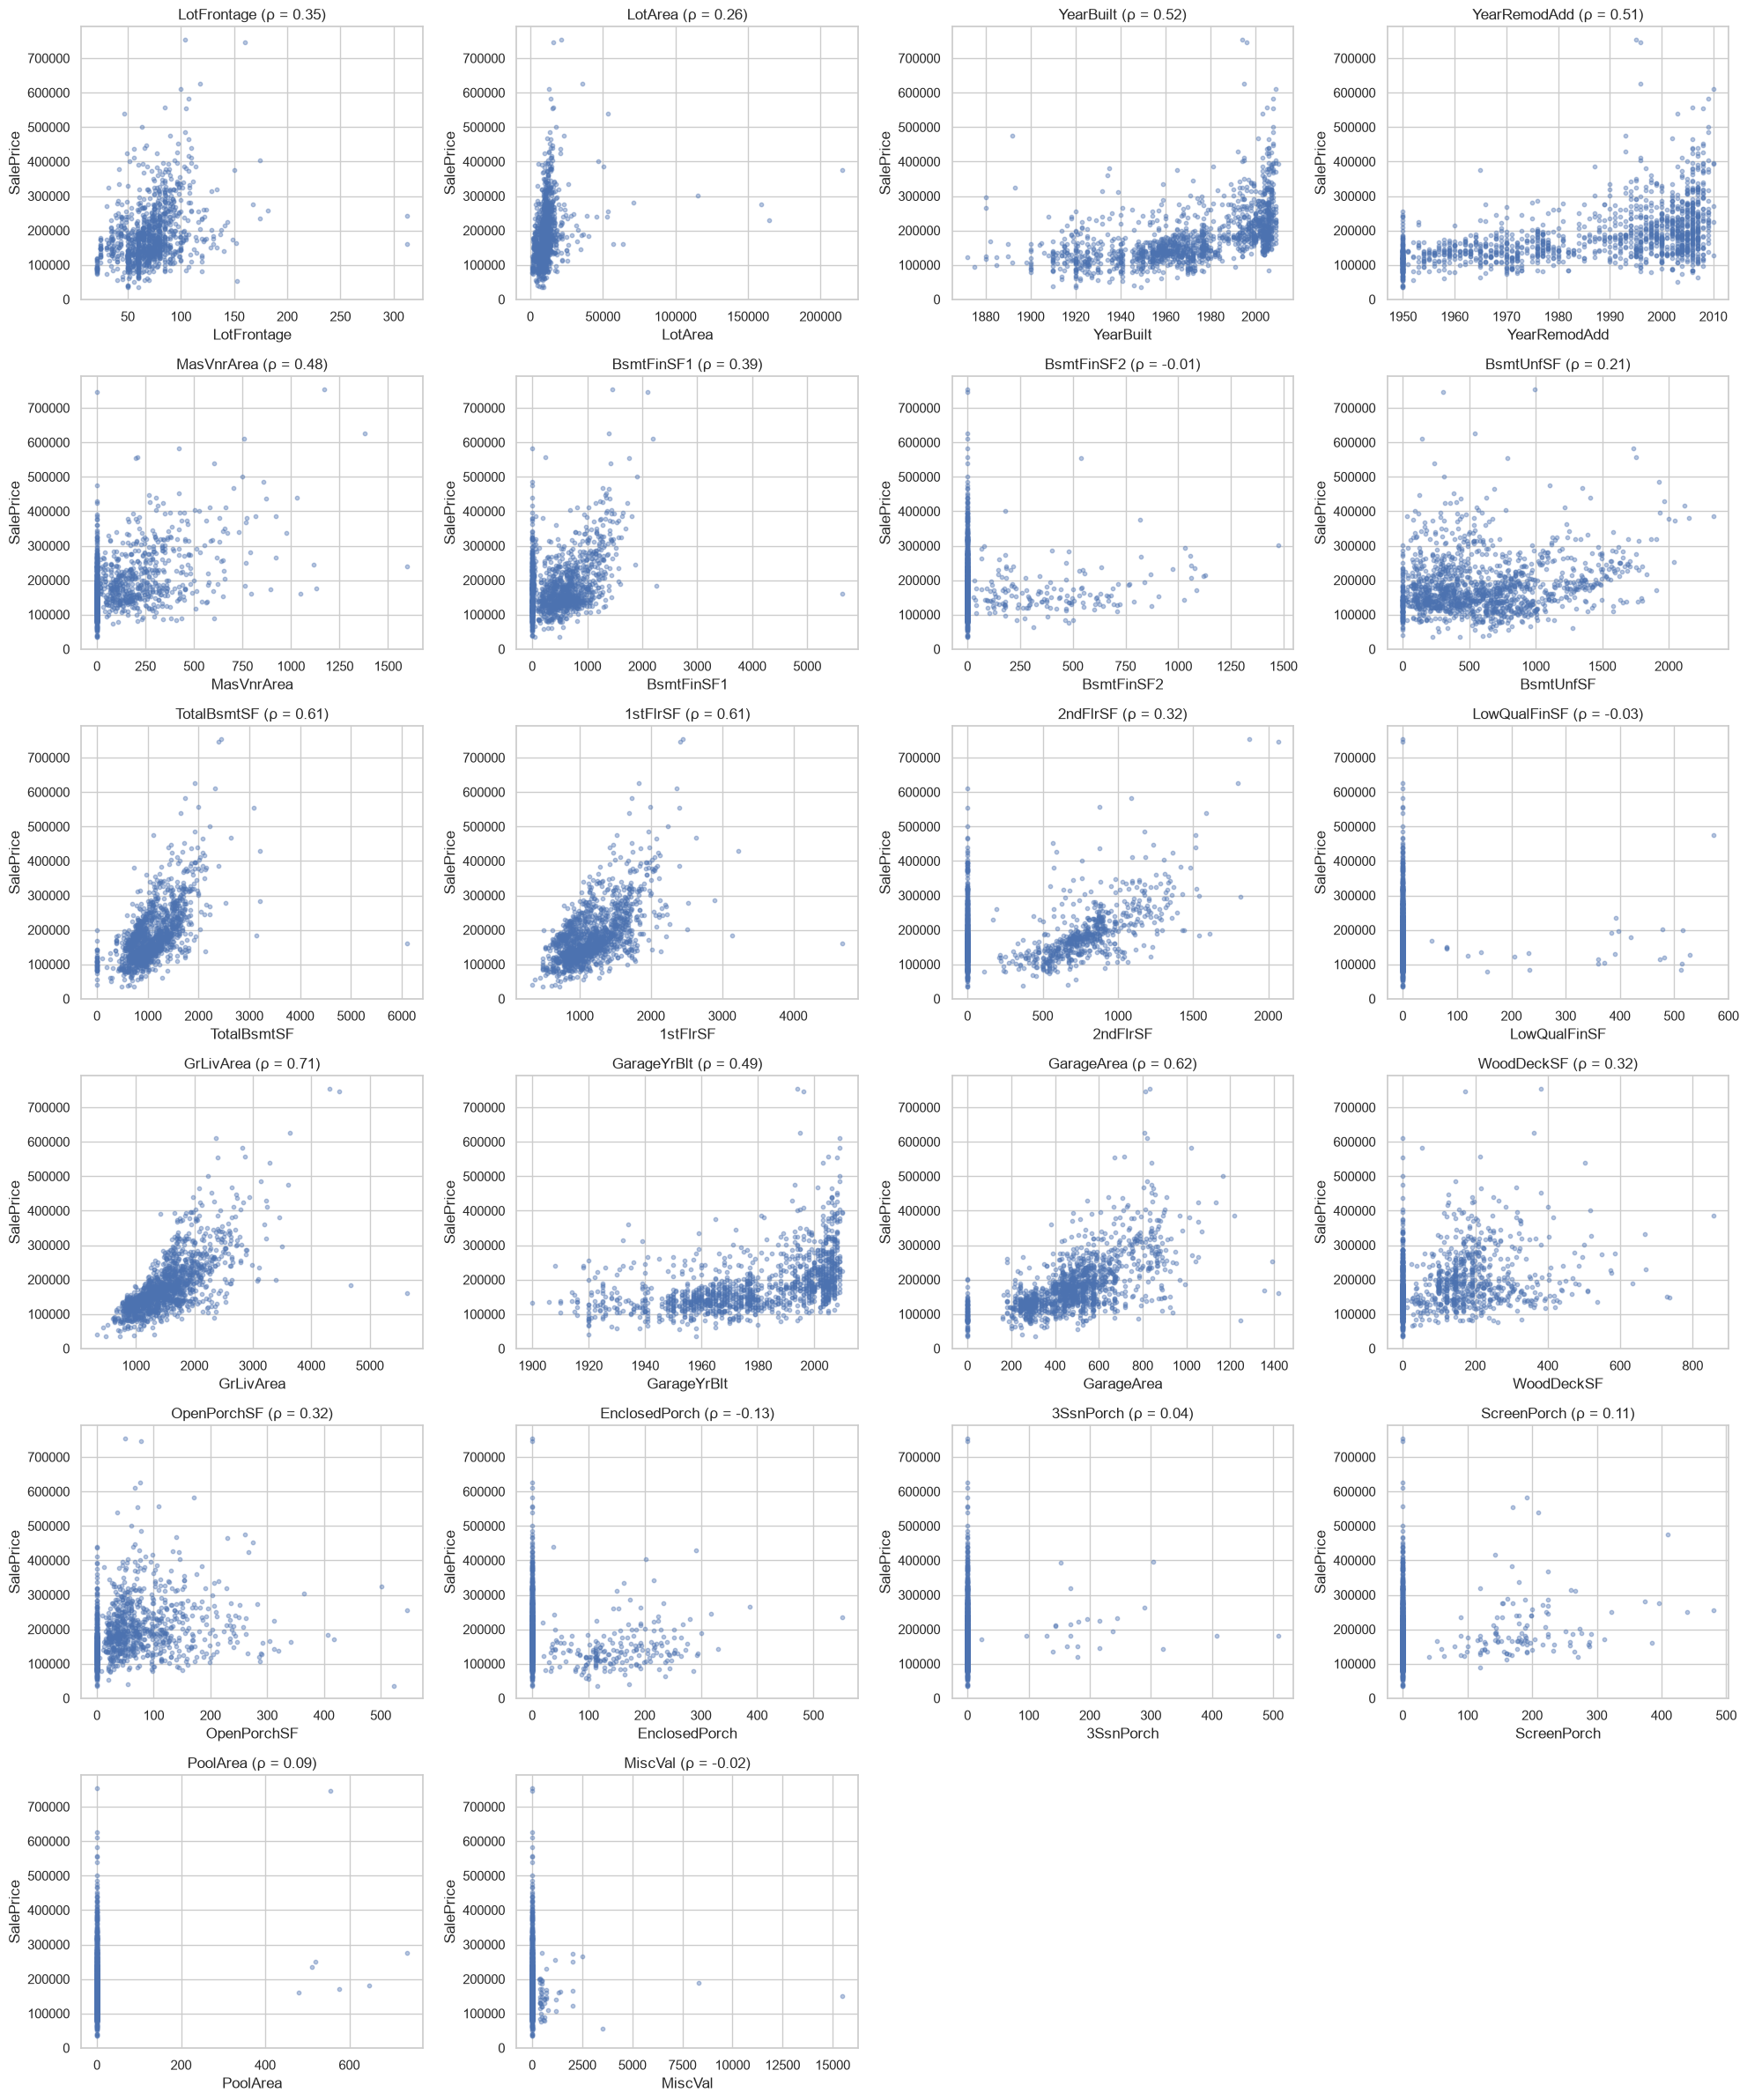

In [5]:
# Scatter plot de cada variable continua contra SalePrice
n_cols = 4
n_rows = int(np.ceil(len(continuas) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
axes = axes.flatten()

correlations = {}
for ax, col in zip(axes, continuas):
    rho = train[col].corr(train[TARGET])
    correlations[col] = rho
    ax.scatter(train[col], train[TARGET], alpha=0.4, s=10)
    ax.set_title(f"{col} (ρ = {rho:.2f})")
    ax.set_xlabel(col)
    ax.set_ylabel(TARGET)

# Ocultar los espacios vacíos de la cuadrícula
for ax in axes[len(continuas):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

## 6. Ranking de correlación de las variables continuas con `SalePrice`

Se reúnen en una tabla los coeficientes de correlación (ρ) calculados en el paso anterior, ordenados de mayor a menor. Las variables de arriba son las que más aumentan junto con el precio y las de abajo las que se mueven en sentido contrario.

La columna `abs_correlacion` muestra la fuerza de la relación sin importar su dirección (positiva o negativa), lo que ayuda a identificar las variables con mayor potencial para predecir el precio.

In [6]:
# Tabla de correlaciones con SalePrice, ordenada de mayor a menor
corr_df = (
    pd.DataFrame({"variable": correlations.keys(), "correlacion": correlations.values()})
    .assign(abs_correlacion=lambda df: df["correlacion"].abs())
    .sort_values("correlacion", ascending=False)
    .reset_index(drop=True)
)
corr_df

,variable,correlacion,abs_correlacion
0,GrLivArea,0.708624,0.708624
1,GarageArea,0.623431,0.623431
2,TotalBsmtSF,0.613581,0.613581
3,1stFlrSF,0.605852,0.605852
4,YearBuilt,0.522897,0.522897
5,YearRemodAdd,0.507101,0.507101
6,GarageYrBlt,0.486362,0.486362
7,MasVnrArea,0.477493,0.477493
8,BsmtFinSF1,0.386420,0.386420
9,LotFrontage,0.351799,0.351799


## 7. Relación de las variables discretas con `SalePrice`

Para las variables discretas se usa un **diagrama de caja (boxplot)** por cada variable: en el eje X están sus posibles valores y en el eje Y el precio de venta. Cada caja resume los precios de las viviendas que tienen ese valor:

- La **línea central** de la caja es la mediana del precio.
- La **caja** abarca el 50 % central de los precios.
- Los **bigotes** muestran el rango habitual de precios.

Sobre cada caja se dibujan también las viviendas individuales como **puntos** (con un pequeño desplazamiento horizontal aleatorio para que no se encimen). Así se ve cuántas viviendas hay en cada valor: una caja con pocos puntos es menos confiable que una con muchos. Si las cajas suben o bajan de forma ordenada a lo largo del eje X, la variable tiene relación con el precio.

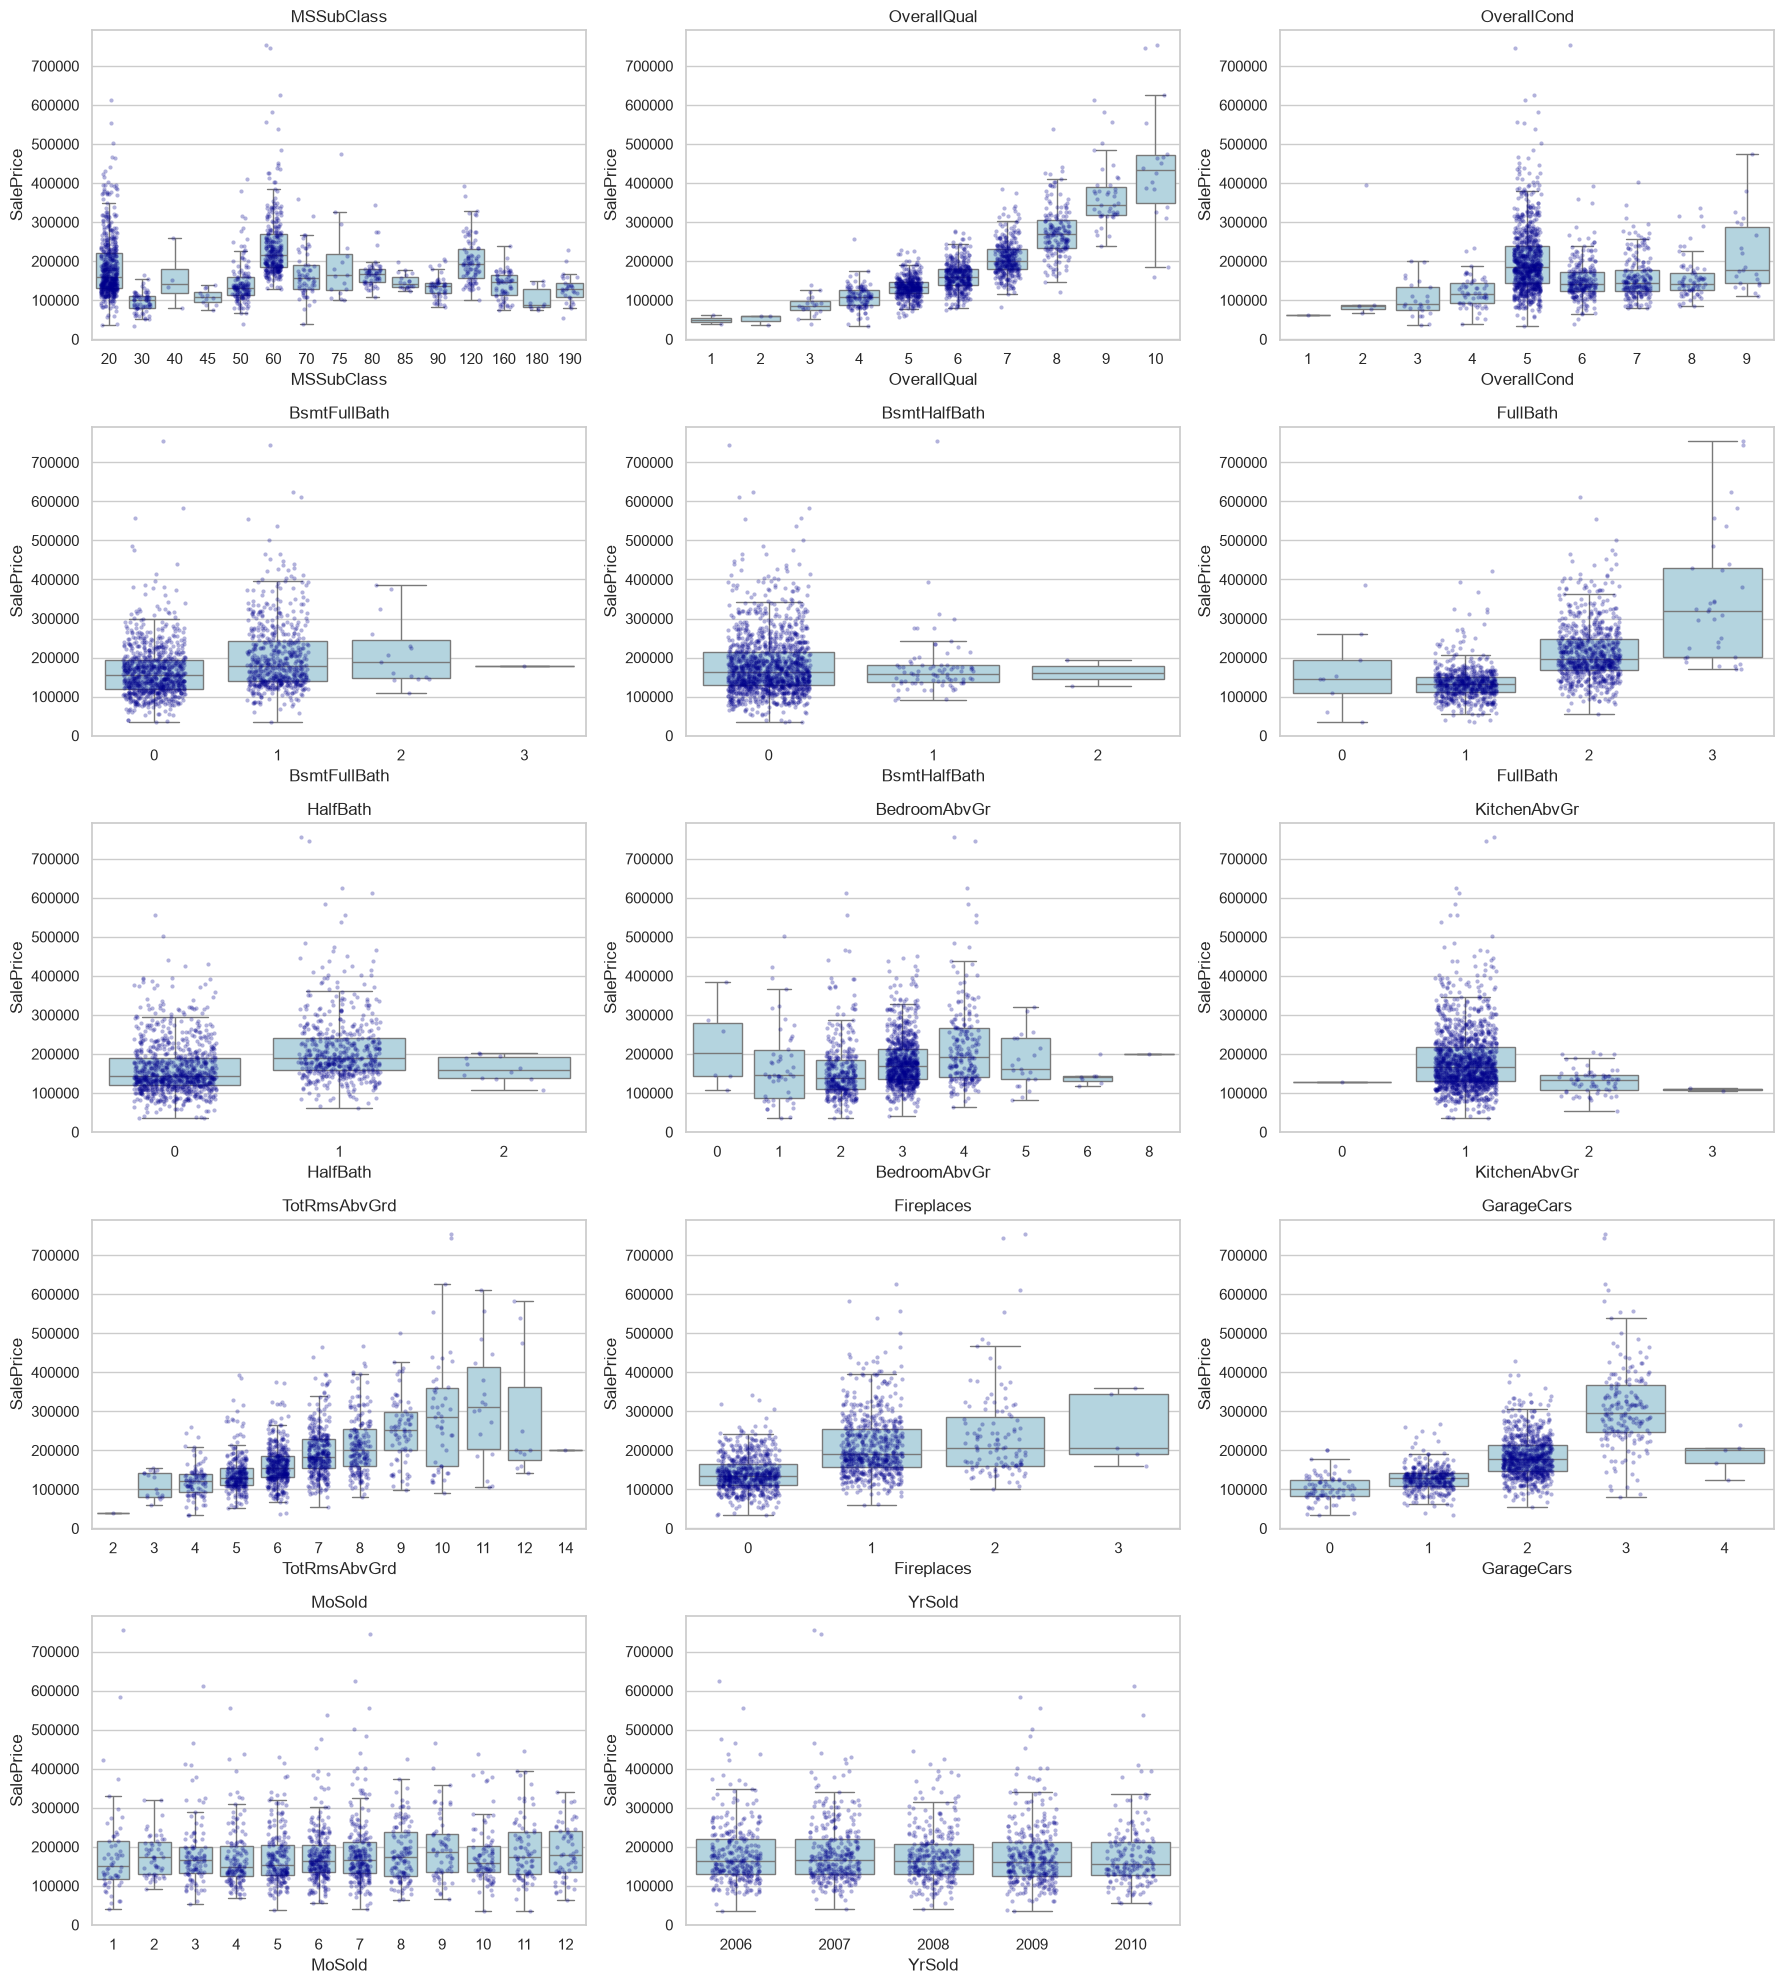

In [7]:
# Boxplot con puntos de cada variable discreta contra SalePrice
n_cols = 3
n_rows = int(np.ceil(len(discretas) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4 * n_rows))
axes = axes.flatten()

for ax, col in zip(axes, discretas):
    sns.boxplot(data=train, x=col, y=TARGET, ax=ax, color="lightblue", showfliers=False)
    sns.stripplot(data=train, x=col, y=TARGET, ax=ax, color="darkblue", alpha=0.3, size=3, jitter=0.25)
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel(TARGET)

# Ocultar los espacios vacíos de la cuadrícula
for ax in axes[len(discretas):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

## 8. Relación de las variables categóricas con `SalePrice`

Las variables categóricas (por ejemplo, el barrio o el tipo de calefacción) no son números, así que no se les puede calcular la correlación de Pearson. En su lugar se usa la **razón de correlación η (eta)**, que responde a la pregunta: *¿qué parte de las diferencias de precio entre viviendas se explica por la categoría a la que pertenecen?*

Se calcula así:

1. Se agrupan las viviendas por categoría y se calcula el precio promedio de cada grupo.
2. Se mide cuánto se alejan esos promedios del precio promedio general (**variación entre grupos**).
3. Se mide cuánto varían todos los precios respecto al promedio general (**variación total**).
4. η es la raíz cuadrada del cociente entre ambas: $\eta = \sqrt{\dfrac{\text{variación entre grupos}}{\text{variación total}}}$

Su valor va de **0** (la categoría no ayuda a explicar el precio) a **1** (la categoría explica por completo el precio). Se interpreta como el valor absoluto de ρ: indica la fuerza de la relación, pero no tiene dirección, porque las categorías no tienen un orden.

En este dataset, un valor vacío en una categórica casi siempre significa que la vivienda **no tiene** esa característica (por ejemplo, `PoolQC` vacío = sin piscina). Por eso los vacíos se agrupan en una categoría propia llamada `"Sin dato"` en lugar de descartarlos.

In [8]:
# Función para calcular la razón de correlación η entre una variable categórica y una numérica
def correlation_ratio(categories, values):
    """Devuelve η: qué parte de la variación de `values` se explica por los grupos de `categories`."""
    df = pd.DataFrame({"cat": categories, "val": values})
    overall_mean = df["val"].mean()
    groups = df.groupby("cat")["val"].agg(["mean", "count"])
    ss_between = (groups["count"] * (groups["mean"] - overall_mean) ** 2).sum()
    ss_total = ((df["val"] - overall_mean) ** 2).sum()
    return np.sqrt(ss_between / ss_total)

Para cada variable categórica se dibuja un **boxplot** con las categorías en el eje X y `SalePrice` en el eje Y, con el valor de η en el título. Como en las variables discretas, se agregan las viviendas individuales como **puntos** para ver cuántas hay en cada categoría.

Las categorías se ordenan de menor a mayor según su precio mediano, para que sea fácil ver qué categorías se asocian con viviendas más baratas o más caras.

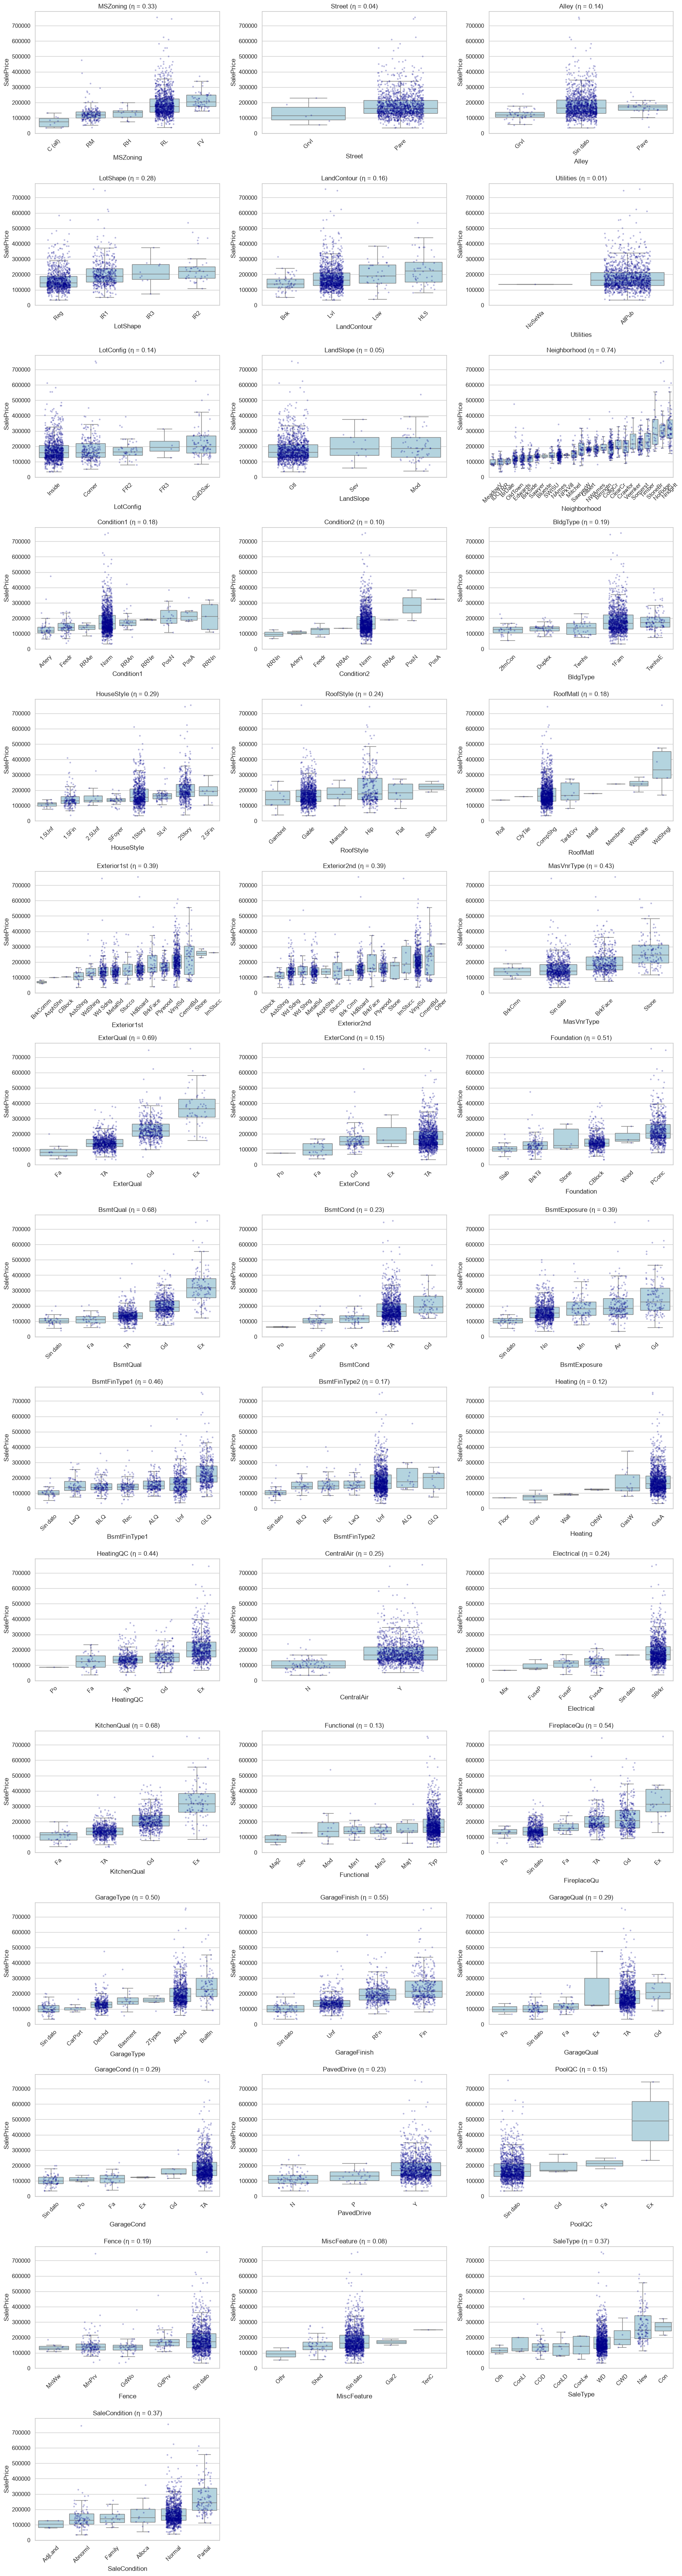

In [9]:
# Boxplot con puntos de cada variable categórica contra SalePrice, con η en el título
categoricas = train.select_dtypes(exclude="number").columns.tolist()
train_cat = train[categoricas].fillna("Sin dato")

n_cols = 3
n_rows = int(np.ceil(len(categoricas) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4.5 * n_rows))
axes = axes.flatten()

eta_values = {}
for ax, col in zip(axes, categoricas):
    eta = correlation_ratio(train_cat[col], train[TARGET])
    eta_values[col] = eta
    order = train[TARGET].groupby(train_cat[col]).median().sort_values().index
    sns.boxplot(x=train_cat[col], y=train[TARGET], order=order, ax=ax, color="lightblue", showfliers=False)
    sns.stripplot(x=train_cat[col], y=train[TARGET], order=order, ax=ax, color="darkblue", alpha=0.3, size=3, jitter=0.25)
    ax.set_title(f"{col} (η = {eta:.2f})")
    ax.set_xlabel(col)
    ax.set_ylabel(TARGET)
    ax.tick_params(axis="x", rotation=45)

# Ocultar los espacios vacíos de la cuadrícula
for ax in axes[len(categoricas):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

## 9. Selección de variables para el modelo

Se eligen las **10 variables más relacionadas con `SalePrice`** de cada grupo, usando la métrica adecuada para cada tipo:

| Grupo | Métrica | Por qué |
|---|---|---|
| Continuas | \|ρ\| (valor absoluto de Pearson) | Una relación negativa fuerte es tan útil como una positiva, así que se ordena por la fuerza sin importar el signo. |
| Discretas | η (razón de correlación) | Algunas son códigos sin un orden numérico real (por ejemplo, `MSSubClass` identifica el tipo de vivienda), así que se tratan como grupos, igual que en sus boxplots. |
| Categóricas | η (razón de correlación) | Es la métrica calculada en la sección anterior. |

Las tres listas se unen en `modelo_features`, que será el conjunto de variables con el que se construirá el modelo.

In [10]:
# Top 10 de variables por grupo según su métrica de relación con SalePrice
TOP_N = 10

ranking_continuas = (
    pd.Series({col: abs(correlations[col]) for col in continuas}, name="abs_correlacion")
    .sort_values(ascending=False)
)
ranking_discretas = (
    pd.Series({col: correlation_ratio(train[col], train[TARGET]) for col in discretas}, name="eta")
    .sort_values(ascending=False)
)
ranking_categoricas = pd.Series(eta_values, name="eta").sort_values(ascending=False)

top_continuas = ranking_continuas.head(TOP_N).index.tolist()
top_discretas = ranking_discretas.head(TOP_N).index.tolist()
top_categoricas = ranking_categoricas.head(TOP_N).index.tolist()

modelo_features = top_continuas + top_discretas + top_categoricas

print(f"Continuas:   {top_continuas}")
print(f"Discretas:   {top_discretas}")
print(f"Categóricas: {top_categoricas}")
print(f"\nTotal de features: {len(modelo_features)}")

Continuas:   ['GrLivArea', 'GarageArea', 'TotalBsmtSF', '1stFlrSF', 'YearBuilt', 'YearRemodAdd', 'GarageYrBlt', 'MasVnrArea', 'BsmtFinSF1', 'LotFrontage']
Discretas:   ['OverallQual', 'GarageCars', 'FullBath', 'TotRmsAbvGrd', 'MSSubClass', 'Fireplaces', 'OverallCond', 'HalfBath', 'BedroomAbvGr', 'BsmtFullBath']
Categóricas: ['Neighborhood', 'ExterQual', 'BsmtQual', 'KitchenQual', 'GarageFinish', 'FireplaceQu', 'Foundation', 'GarageType', 'BsmtFinType1', 'HeatingQC']

Total de features: 30


## 10. Guardar las features en el archivo de configuración

La lista `modelo_features` se guarda en `pipeline_config.yaml`, en la raíz del proyecto, bajo la clave `MODEL_FEATURES`. Así, los siguientes pasos del proyecto (preparación de datos, entrenamiento y predicción) leen las variables desde un único lugar, sin tener que volver a ejecutar este notebook ni copiar la lista a mano.

Si el archivo ya existe, solo se actualiza `MODEL_FEATURES` y se conservan las demás configuraciones que contenga.

In [11]:
# Guardar MODEL_FEATURES en pipeline_config.yaml
import yaml

CONFIG_FILE = PROJECT_ROOT / "pipeline_config.yaml"

config = yaml.safe_load(CONFIG_FILE.read_text(encoding="utf-8")) if CONFIG_FILE.exists() else {}
config = config or {}
config["MODEL_FEATURES"] = modelo_features

CONFIG_FILE.write_text(yaml.safe_dump(config, sort_keys=False, allow_unicode=True), encoding="utf-8")
print(f"Configuración guardada en: {CONFIG_FILE.relative_to(PROJECT_ROOT)}")

Configuración guardada en: pipeline_config.yaml
